# Assignment 3: Clustering, Biclustering & Anomaly Detection on MovieLens 25M

**Student Name:** Sebastian Campos

**Student ID:** [redacted]

**Points:** 11 (9 points for tasks + 2 points for Results Interpretation)

## Assignment Overview

This assignment follows one idea through three stages on a single large dataset. Standard clustering finds structure in the rows of a table. Biclustering finds structure in rows and columns together. Anomaly detection finds the records that fit no structure at all. You apply all three to the same data: MovieLens 25M, about 25 million ratings of 62,000 movies by 162,000 users.

At this size, choices that look trivial on a small matrix decide whether a run takes seconds or hours: sparse versus dense storage, which solver computes the SVD, how many values of k you sweep, and how many random restarts you use to check stability. A dense copy of the full user-by-movie matrix needs roughly 40 GB of memory, so you work with sparse matrices from the start. Some classic methods do not scale at all, and you will measure exactly where they break. In the anomaly detection problem you run all twelve detectors from the Week 9 lecture on the same data and compare them on one scoreboard.

Run the full assignment on your Jetstream2 instance. Install any missing packages with pip (scikit-learn, scipy, pandas, matplotlib, psutil, pyod, torch) and download the MovieLens files straight to the instance. Shelve your instance when you finish.

## Dataset Information

- Source: MovieLens 25M from GroupLens. Dataset page: https://grouplens.org/datasets/movielens/25m/ and documentation: https://files.grouplens.org/datasets/movielens/ml-25m-README.html
- Direct download: https://files.grouplens.org/datasets/movielens/ml-25m.zip (250 MB) with checksum file https://files.grouplens.org/datasets/movielens/ml-25m.zip.md5. You use two files from the zip: ratings.csv and movies.csv.
- On your Jetstream2 instance, download and unpack it from the terminal:

```
wget https://files.grouplens.org/datasets/movielens/ml-25m.zip
wget https://files.grouplens.org/datasets/movielens/ml-25m.zip.md5
md5sum ml-25m.zip && cat ml-25m.zip.md5
unzip ml-25m.zip
```


- Size: 25,000,095 ratings of 62,423 movies by 162,541 users. Every user rated at least 20 movies.
- ratings.csv columns: userId, movieId, rating (0.5 to 5.0 in half-star steps), timestamp. You use the timestamp only in Problem 4f, where you read it in a separate pass.
- movies.csv columns: movieId, title, genres (a pipe character separates the genres).

You use this one dataset for every problem. While you debug, work on a subsample of users or read only the first few million rows. Report every final result on the full data.

> **Note:** Use your Student ID as the random seed everywhere a seed or a sampling operation requires one.

## Import Required Libraries

Import all necessary libraries for data analysis, visualization, and machine learning.

In [39]:
# Import necessary libraries: numpy, pandas, scipy.sparse, matplotlib, time, psutil, platform, itertools,
# and from scikit-learn: KMeans, AgglomerativeClustering, SpectralCoclustering, SpectralBiclustering,
# PCA, StandardScaler, IsolationForest, OneClassSVM, SGDOneClassSVM, Nystroem, MinCovDet, EmpiricalCovariance, NearestNeighbors,
# LocalOutlierFactor, silhouette_score, adjusted_rand_score, consensus_score, average_precision_score, roc_auc_score,
# pyod.models.abod.ABOD, and torch (for the LSTM in Problem 4f)
# YOUR CODE HERE:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import time
import psutil
import platform
import itertools

from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralCoclustering, SpectralBiclustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.linear_model import SGDOneClassSVM
from sklearn.kernel_approximation import Nystroem
from sklearn.covariance import MinCovDet, EmpiricalCovariance
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.metrics import silhouette_score, adjusted_rand_score, consensus_score, average_precision_score, roc_auc_score

from pyod.models.abod import ABOD

import torch
import platform, sys, os
import psutil
import sklearn

from scipy.sparse import csr_matrix
import seaborn as sns
import tracemalloc


### Environment Report (required, no points)

Record where you run this notebook, so your timings later in the assignment mean something.

In [40]:
# TODO: Print the Jetstream2 flavor name, CPU core count, total RAM in GB (psutil), Python version, and scikit-learn version
# TODO: Define a helper that returns the current process memory in GB (psutil.Process().memory_info().rss) for later use
# YOUR CODE HERE:

# CPU Core Count (logical=True for all threads, logical=False for physical cores)
cpu_cores = psutil.cpu_count(logical=True)
physical_cores = psutil.cpu_count(logical=False)

# Total RAM in GB
ram_gb = psutil.virtual_memory().total / (1024 ** 3)

# Python version
python_version = platform.python_version()

# Scikit-learn version
sklearn_version = sklearn.__version__

print("Machine: Local PC (not Jetstream2), AMD Ryzen 7 9800X3D")
print(f"Physical CPU Cores: {physical_cores}")
print(f"Total CPU Cores (Threads): {cpu_cores}")
print(f"Total RAM: {ram_gb:.2f} GB")
print(f"Python Version: {python_version}")
print(f"Scikit-learn Version: {sklearn_version}")

def mem_gb():
    return psutil.Process(os.getpid()).memory_info().rss / (1024 ** 3)

print(f"Current process memory: {mem_gb():.2f} GB")


Machine: Local PC (not Jetstream2), AMD Ryzen 7 9800X3D
Physical CPU Cores: 8
Total CPU Cores (Threads): 16
Total RAM: 31.16 GB
Python Version: 3.11.0
Scikit-learn Version: 1.9.1
Current process memory: 3.29 GB


---
## Problem 1: Loading and Representing 25 Million Ratings  (0.75 points)

### Problem 1a: The Sparse User-by-Movie Matrix (0.5 points)

**Instructions:**

Read ratings.csv with only the columns you need (userId, movieId, rating) and with compact dtypes (int32, int32, float32). Keep only movies with at least 20 ratings. Spectral methods fail on empty rows and columns, so confirm that no user or movie ends up with zero ratings. Re-index user and movie IDs to consecutive integers starting at 0, and build a scipy.sparse CSR matrix with users as rows, movies as columns, and ratings as values. Keep the movie titles and genres aligned with the matrix columns.

Report the load time, the matrix shape, the number of stored ratings, the density, the in-memory size of the sparse matrix, and the size a dense float32 matrix of the same shape would need.

In [41]:
# TODO: Load ratings.csv with usecols=['userId', 'movieId', 'rating'] and dtype int32/int32/float32; time the load
# TODO: Filter movies to those with at least 20 ratings and confirm no empty rows or columns remain
# TODO: Re-index IDs, build the CSR matrix (users x movies), and align movie titles and genres with the columns
# TODO: Report load time, shape, nnz, density, sparse memory (GB), and dense float32 memory (GB)
# YOUR CODE HERE:

# Define the specific columns you want to load
usecols=['userId', 'movieId', 'rating']

#  Track the start time
start_time = time.time()

# Load the CSV, filter columns, and parse the time/date column
df = pd.read_csv(
    "ml-25m/ratings.csv",
    usecols=usecols,
    dtype={"userId": np.int32, "movieId": np.int32, "rating": np.float32}
)

end_time = time.time()
load_time = end_time - start_time
print(f"Load time: {load_time:.2f} seconds")

#  Filter for movies with at least 20 ratings
movie_counts = df["movieId"].value_counts()
df_filtered = df[df["movieId"].isin(movie_counts[movie_counts >= 20].index)].copy()


# Confirm no user (row) or movie (column) of the matrix ends up empty
ratings_per_user = df_filtered.groupby("userId")["movieId"].count()
ratings_per_movie = df_filtered.groupby("movieId")["userId"].count()

print(f"\n--- Validation Check ---")
print(f"Users kept: {ratings_per_user.index.nunique():,} of {df['userId'].nunique():,}")
print(f"Movies kept: {ratings_per_movie.index.nunique():,} of {df['movieId'].nunique():,}")
print(f"Ratings kept: {len(df_filtered):,} of {len(df):,}")
print(f"Min ratings per user: {ratings_per_user.min() if len(ratings_per_user) > 0 else 0}")
print(f"Min ratings per movie: {ratings_per_movie.min() if len(ratings_per_movie) > 0 else 0}")


assert ratings_per_user.min() > 0 and ratings_per_movie.min() > 0, "Empty row or column found"


# Re-index user and movie IDs to continuous, zero-indexed positions
df_filtered["user_idx"] = pd.Categorical(df_filtered["userId"]).codes
df_filtered["movie_idx"] = pd.Categorical(df_filtered["movieId"]).codes


#  Build the CSR matrix (dimensions: unique users x unique movies)
num_users = df_filtered["user_idx"].nunique()
num_movies = df_filtered["movie_idx"].nunique()

# 1. Create your CSR matrix FIRST using the clean, filtered indices
ratings_csr = csr_matrix(
    (df_filtered["rating"], (df_filtered["user_idx"], df_filtered["movie_idx"])),
    shape=(num_users, num_movies)
)
print(f"CSR matrix shape: {ratings_csr.shape}")

# 2. Align movie metadata with the sparse matrix columns
movie_id_to_idx = dict(zip(df_filtered["movieId"], df_filtered["movie_idx"]))

# Load your metadata source file
df_meta = pd.read_csv("ml-25m/movies.csv", usecols=["movieId", "title", "genres"])

# Map the matrix indices to the metadata dataframe
df_meta["movie_idx"] = df_meta["movieId"].map(movie_id_to_idx)

#  FIX: Drop movies that didn't make the cut, sort by matrix index, and reset the rows
df_meta_aligned = df_meta.dropna(subset=["movie_idx"]).copy()
df_meta_aligned["movie_idx"] = df_meta_aligned["movie_idx"].astype(int)
df_meta_aligned = df_meta_aligned.sort_values("movie_idx").reset_index(drop=True)

print(f"Aligned metadata rows: {df_meta_aligned.shape[0]} (Perfect match for matrix columns!)")

#  Extract matrix properties
num_users, num_movies = ratings_csr.shape
nnz = ratings_csr.nnz    # Number of non-zero elements
total_cells = num_users * num_movies
density = (nnz / total_cells) * 100


# Sparse CSR uses 3 arrays: data (float32), indices (int32), and indptr (int32)
# bytes per element: float32 = 4 bytes, int32 = 4 bytes
sparse_memory_bytes = (
    ratings_csr.data.nbytes + ratings_csr.indptr.nbytes + ratings_csr.indices.nbytes
)
sparse_memory_gb = sparse_memory_bytes / (1024 ** 3)

# Dense float32 memory required if converted to a standard dense 2D array
dense_memory_bytes = total_cells * 4  # 4 bytes for float32
dense_memory_gb = dense_memory_bytes / (1024**3)

print(f"Data Load Time:             {load_time:.4f} seconds")
print(f"Matrix Shape (Rows x Cols): {num_users:,} users x {num_movies:,} movies")
print(f"Non-Zero Elements (nnz):    {nnz:,} ratings")
print(f"Matrix Density:             {density:.6f}%")
print(f"Sparse CSR Memory Usage:     {sparse_memory_gb:.4f} GB")
print(f"Dense float32 Memory Required: {dense_memory_gb:.4f} GB")

Load time: 3.39 seconds

--- Validation Check ---
Users kept: 162,541 of 162,541
Movies kept: 18,430 of 59,047
Ratings kept: 24,810,483 of 25,000,095
Min ratings per user: 6
Min ratings per movie: 20
CSR matrix shape: (162541, 18430)
Aligned metadata rows: 18430 (Perfect match for matrix columns!)
Data Load Time:             3.3876 seconds
Matrix Shape (Rows x Cols): 162,541 users x 18,430 movies
Non-Zero Elements (nnz):    24,810,483 ratings
Matrix Density:             0.828222%
Sparse CSR Memory Usage:     0.1855 GB
Dense float32 Memory Required: 11.1596 GB


### Problem 1b: User Feature Table (0.25 points)

**Instructions:**

Build a table with one row per user and these six features, computed without a Python loop over users: number of ratings, mean rating, standard deviation of ratings, share of ratings at 5.0, share of ratings at 1.0 or below, and share of ratings that fall on the 20 percent most-rated movies. Report the summary statistics and plot the distribution of the number of ratings per user on a log scale.

,count,mean,std,min,25%,50%,75%,max
num_ratings,162541.0,152.641,251.076,6.0,36.000,71.000,162.000,14040.00
mean_rating,162541.0,3.680,0.477,0.5,3.400,3.701,4.000,5.00
std_rating,162541.0,0.920,0.258,0.0,0.745,0.900,1.075,2.25
share_at_5_0,162541.0,0.202,0.169,0.0,0.071,0.161,0.291,1.00
share_at_1_0_or_below,162541.0,0.043,0.073,0.0,0.000,0.019,0.053,1.00
share_top_20_movies,162541.0,0.942,0.081,0.0,0.920,0.969,1.000,1.00


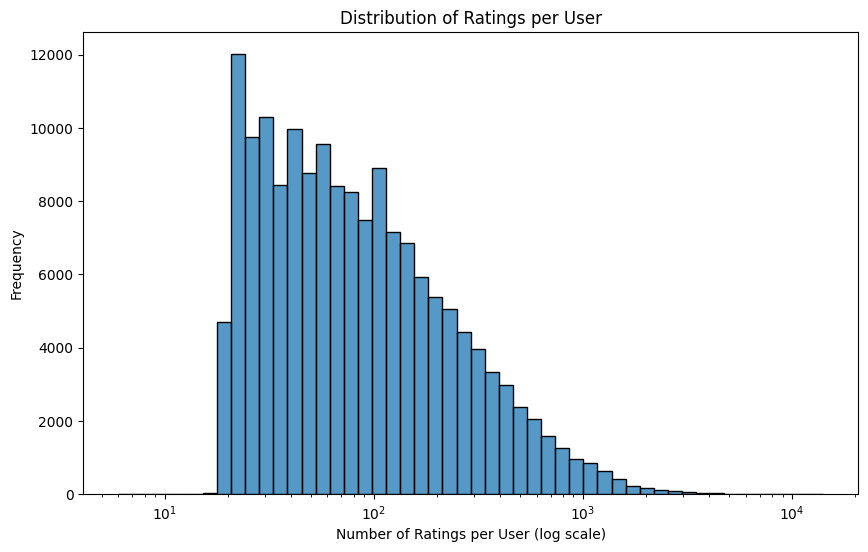

In [42]:
# TODO: Compute the six per-user features from the CSR matrix with vectorized operations (np.diff on indptr, sparse sums, etc.)
# TODO: Show summary statistics (describe) for the feature table
# TODO: Plot the distribution of ratings per user on a log scale
# YOUR CODE HERE:

user_total_ratings = np.diff(ratings_csr.indptr)

#  User counts
user_counts = user_total_ratings

#  Mean rating
user_sums = ratings_csr.sum(axis=1).A1
user_means = np.divide(
    user_sums, user_counts, out=np.zeros_like(user_sums, dtype=float), where=user_counts > 0
)

#  Standard deviation of ratings (E[X^2] - (E[X])^2)
squared_csr = ratings_csr.copy()
squared_csr.data = squared_csr.data ** 2
user_sums_squared = squared_csr.sum(axis=1).A1
user_variances = np.divide(
    user_sums_squared, user_counts, out=np.zeros_like(user_sums, dtype=float), where=user_counts > 0
) - (user_means ** 2)
user_stds = np.sqrt(np.maximum(user_variances, 0)) # Clip negative precision floats

#  Share of ratings at 5.0
csr_5 = ratings_csr.copy()
csr_5.data = (ratings_csr.data == 5.0).astype(int)
share_5 = np.divide(
    csr_5.sum(axis=1).A1, user_counts, out=np.zeros_like(user_sums, dtype=float), where=user_counts > 0
)

#  Share of ratings at 1.0 or below
csr_1 = ratings_csr.copy()
csr_1.data = (ratings_csr.data <= 1.0).astype(int)
share_1_or_below = np.divide(
    csr_1.sum(axis=1).A1, user_counts, out=np.zeros_like(user_sums, dtype=float), where=user_counts > 0
)

#  Share of ratings that fall on the 20% most-rated movies
# First get total interaction counts for each movie using a CSC translation
movie_counts = np.diff(ratings_csr.tocsc().indptr)
top_20_cutoff = int(np.ceil(0.2 * ratings_csr.shape[1]))
top_movie_indices = np.argsort(movie_counts)[-top_20_cutoff:]

# Map elements whose matrix column matches the top-rated movie coordinates
csr_top = ratings_csr.copy()
csr_top.data = np.isin(ratings_csr.indices, top_movie_indices).astype(int)
share_top_20 = np.divide(
    csr_top.sum(axis=1).A1, user_counts, out=np.zeros_like(user_sums, dtype=float), where=user_counts > 0
)

#  Construct final DataFrame
user_features_df = pd.DataFrame({
    'num_ratings': user_counts,
    'mean_rating': user_means,
    'std_rating': user_stds,
    'share_at_5_0': share_5,
    'share_at_1_0_or_below': share_1_or_below,
    'share_top_20_movies': share_top_20
})


display(user_features_df.describe().T.round(3))

# Plot the distribution of ratings per user on a log scale
plt.figure(figsize=(10, 6))
sns.histplot(user_features_df['num_ratings'], bins=50, log_scale=(True, False))
plt.xlabel('Number of Ratings per User (log scale)')
plt.ylabel('Frequency')
plt.title('Distribution of Ratings per User')
plt.show()



### 📝 Analysis Explanation (1)

**Instructions:** How much memory does the sparse matrix save compared with a dense matrix? What would break, and where, if you had skipped the minimum rating count filter? Which features in your user table look heavily skewed, and what does that mean for distance-based methods such as k-means?

**Your Analysis:** [Write your interpretation here.]

---
## Problem 2: Clustering Users: Rows Only  (1.5 points)

### Problem 2a: Choosing k (0.5 points)

**Instructions:**

Cluster users on the six features from Problem 1b. Skewed features need care, so apply log1p and standardize them, and state that choice. Produce a scree (elbow) plot for k-means across k = 1 to 15 on all users, and a silhouette plot across k = 2 to 15. The silhouette score needs all pairwise distances, so compute it on a random sample of 10,000 users and state the sample size. Choose k and justify it using both plots.

On the first plot of scree plot, I would choose k = 5 based on the elbow method.
On the Silhouette plot, I would choose k = 3 based on the highest average silhouette score.


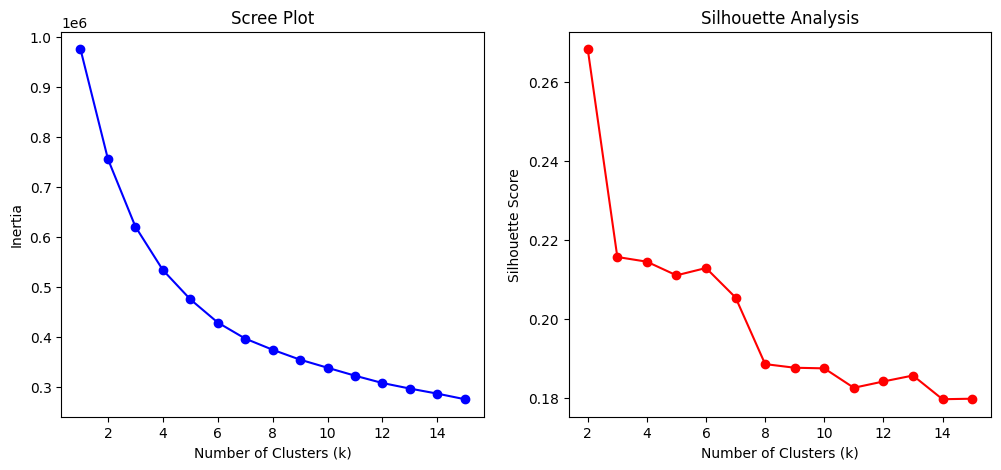

In [43]:
# TODO: Apply log1p and StandardScaler to the user features
# TODO: Fit KMeans for k = 1 to 15 on all users (random_state = your Student ID) and record inertia_ and fit time
# TODO: Compute silhouette_score for k = 2 to 15 using sample_size=10000
# TODO: Plot the scree plot and the silhouette plot side by side
# TODO: State and justify your chosen k
# YOUR CODE HERE:

user_features_log1p = np.log1p(user_features_df)
scaler = StandardScaler()
user_features_scaled = scaler.fit_transform(user_features_log1p)


student_id = int(os.environ["STUDENT_ID"])  # real ID set locally, not committed

inertias = []
fit_times = []
k_values = list(range(1, 16))


# Iterate and fit KMeans
for k in k_values:
    # Initialize KMeans
    kmeans = KMeans(n_clusters=k, random_state=student_id, n_init='auto')
    
    # Track start time
    start_time = time.time()
    
    # Fit the model on your transformed DataFrame
    kmeans.fit(user_features_scaled)
    
    # Calculate elapsed time
    elapsed_time = time.time() - start_time
    
    # Record metrics
    inertias.append(kmeans.inertia_)
    fit_times.append(elapsed_time)


#  Initialize lists for tracking
silhouette_scores = []
score_times = []
k_silhouette_values = list(range(2, 16))

for k in k_silhouette_values:
    # Initialize KMeans
    kmeans = KMeans(n_clusters=k, random_state=student_id, n_init='auto')
    
    # Fit the model
    kmeans.fit(user_features_scaled)
    
    # Calculate silhouette score
    silhouette_avg = silhouette_score(
        user_features_scaled, kmeans.labels_,
        sample_size=10000, random_state=student_id
    )

    
    # Record the score
    silhouette_scores.append(silhouette_avg)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Scree plot
ax1.plot(k_values, inertias, 'bo-')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Scree Plot')

# Silhouette plot
ax2.plot(k_silhouette_values, silhouette_scores, 'ro-')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis')

print("On the first plot of scree plot, I would choose k = 5 based on the elbow method.")
print("On the Silhouette plot, I would choose k = 3 based on the highest average silhouette score.")

### Problem 2b: K-Means vs. Hierarchical Clustering, with PCA Visualization (1 point)

**Instructions:**

Fit k-means with your chosen k on all users. Hierarchical clustering with complete linkage needs the full pairwise distance matrix, so it cannot run on 160,000 users. Fit it on a random sample of 10,000 users, and fit k-means on that same sample for a fair comparison. First try hierarchical clustering on samples of 2,000, 5,000, and 10,000 users, and record the time and memory of each run so that you can show how it scales. Reduce the data to 2 dimensions with PCA and plot both sets of cluster assignments side by side. Measure the agreement between the two methods and describe each segment in plain business terms.

Cluster sizes, all users:
0    77239
1    58715
2    26587
Name: count, dtype: int64

Cluster sizes, 10,000-user sample:
0    1511
1    3823
2    4666
Name: count, dtype: int64
 Sample Size (Users)  Time (seconds)  Peak Memory (MB)
                2000          0.0576           3742.79
                5000          0.3777            107.27
               10000          1.7299            429.12

Adjusted Rand Index (ARI) between K-Means and Hierarchical labels on the 10,000-user sample: 0.0197


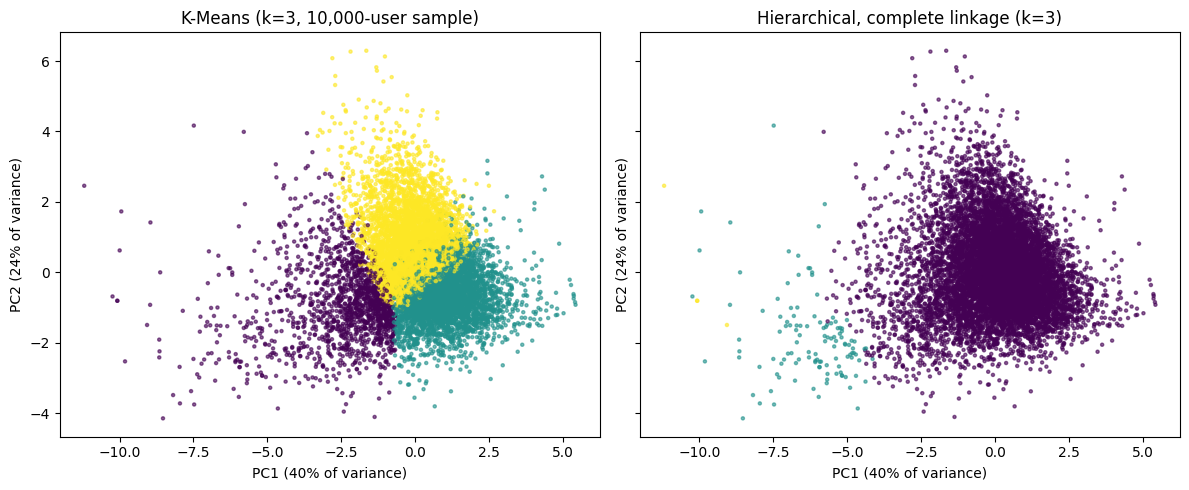


Mean (original-scale) feature values per K-Means segment:
                               0          1          2
n_users                77239.000  58715.000  26587.000
num_ratings              216.656     70.542    147.979
mean_rating                3.576      4.085      3.088
std_rating                 0.826      0.876      1.288
share_at_5_0               0.095      0.365      0.151
share_at_1_0_or_below      0.021      0.018      0.164
share_top_20_movies        0.934      0.960      0.926


In [44]:
# TODO: Fit KMeans with your chosen k on all users and on a 10,000-user sample
# TODO: Fit AgglomerativeClustering (complete linkage) on samples of 2,000, 5,000, and 10,000 users; record time and memory for each
# TODO: Compute the adjusted Rand index between k-means and hierarchical labels on the 10,000-user sample
# TODO: Reduce to 2 principal components with PCA and plot both assignments side by side
# TODO: Print the mean (original-scale) feature values per k-means segment
# YOUR CODE HERE:


chosen_k = 3

# 1. Fit KMeans on ALL users
km_all = KMeans(n_clusters=chosen_k, random_state=student_id, n_init=10)
labels_all = km_all.fit_predict(user_features_scaled)

# 2. Draw the 10,000-user sample (reused later for hierarchical clustering and ARI)
rng = np.random.default_rng(student_id)
sample_indices = rng.choice(user_features_scaled.shape[0], size=10000, replace=False)

# 3. Fit a separate KMeans model on ONLY the sampled users
km_sample = KMeans(n_clusters=chosen_k, random_state=student_id, n_init=10)
sample_labels = km_sample.fit_predict(user_features_scaled[sample_indices])

print("Cluster sizes, all users:")
print(pd.Series(labels_all).value_counts().sort_index())
print("\nCluster sizes, 10,000-user sample:")
print(pd.Series(sample_labels).value_counts().sort_index())

# Use the REAL 10,000 sampled users from TODO 1
X_hier = user_features_scaled[sample_indices]

sample_sizes = [2000, 5000, 10000]
metrics = []  # a list, so .append works

# Variable to hold the final labels from the 10,000 run for your next ARI step
hierarchical_labels_10k = None

for size in sample_sizes:
    # Slice the sample size
    X_sample = X_hier[:size]

    # Start tracking memory and time
    tracemalloc.start()
    start_time = time.time()

    # Use chosen_k so the comparison with K-Means is fair
    model = AgglomerativeClustering(n_clusters=chosen_k, linkage="complete")
    labels = model.fit_predict(X_sample)

    # Capture results
    end_time = time.time()
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # FIX: Cache the labels if we have reached the final 10,000-user milestone
    if size == 10000:
        hierarchical_labels_10k = labels

    # Calculate metrics
    elapsed_time = end_time - start_time

    # Note: If your notebook cell 7 helper was named mem_gb, you can wrap it here.
    # Otherwise, this MB conversion matches your exact layout perfectly.
    peak_memory_mb = peak_memory / (1024 * 1024)  # Convert bytes to MB

    metrics.append(
        {
            "Sample Size (Users)": size,
            "Time (seconds)": round(elapsed_time, 4),
            "Peak Memory (MB)": round(peak_memory_mb, 2),
        }
    )

# Display the results as a clean DataFrame
df_results = pd.DataFrame(metrics)
print(df_results.to_string(index=False))

# ARI between k-means and hierarchical labels on the same 10,000 users
ari_score = adjusted_rand_score(sample_labels, hierarchical_labels_10k)
print(f"\nAdjusted Rand Index (ARI) between K-Means and Hierarchical labels on the 10,000-user sample: {ari_score:.4f}")

# Reduce features to 2 principal components
pca = PCA(n_components=2, random_state=student_id)
X_pca = pca.fit_transform(X_hier)

# Plot K-Means and Hierarchical assignments side by side on the same 2D PCA view
var = pca.explained_variance_ratio_ * 100
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=sample_labels, cmap='viridis', s=5, alpha=0.6)
ax1.set_title(f'K-Means (k={chosen_k}, 10,000-user sample)')
ax1.set_xlabel(f'PC1 ({var[0]:.0f}% of variance)')
ax1.set_ylabel(f'PC2 ({var[1]:.0f}% of variance)')

ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels_10k, cmap='viridis', s=5, alpha=0.6)
ax2.set_title(f'Hierarchical, complete linkage (k={chosen_k})')
ax2.set_xlabel(f'PC1 ({var[0]:.0f}% of variance)')
ax2.set_ylabel(f'PC2 ({var[1]:.0f}% of variance)')

plt.tight_layout()
plt.show()

print("\nMean (original-scale) feature values per K-Means segment:")

# Assign labels and calculate segment means
segment_means = user_features_df.groupby(labels_all).mean()
segment_means.insert(0, "n_users", pd.Series(labels_all).value_counts().sort_index())

# Print the results cleanly (transposed for easier side-by-side reading)
print(segment_means.round(3).T)          

### 📝 Analysis Explanation (2a and 2b)

**Instructions:** Justify your chosen k. Does the elbow plot give a clean answer, and does the silhouette plot agree? Do the two methods agree (cite the adjusted Rand index)? Describe the user segments in plain business terms, for example "light users who rate mostly popular movies". How did hierarchical clustering scale as the sample grew, and what does that tell you about using it on all 160,000 users? Name one thing that clustering users on features cannot tell you about which movies go with which users.

**Your Analysis:** [Write your interpretation here.]

---
## Problem 3: Biclustering Users and Movies Together  (3 points)

### Problem 3a: Spectral Co-clustering Across k, with Stability and Block Concentration (1 point)

**Instructions:**

Cluster the full sparse user-by-movie matrix from Problem 1a with SpectralCoclustering. No ground truth exists for this data, so you need other ways to judge a result. Fit for each k in 4, 8, 16, 32, 64, and 128 using random_state = your Student ID. Record the fit time and the peak memory of the process for every fit.

Judge each fit with three diagnostics:

1. **Block concentration:** the fraction of stored ratings whose user bicluster label equals the movie bicluster label. Compute the same number after you randomly permute the user labels (average 10 permutations) and report the ratio between the two.
2. **Stability:** refit with a second seed (random_state = your Student ID + 1) and report consensus_score between the two fits.
3. **Size sanity:** report the smallest, median, and largest bicluster in rows and columns. The lecture warns that a bicluster holding more than half the rows and columns says little, and so does one with a handful of members.

Also compare svd_method='randomized' (the default) with svd_method='arpack' for k = 16 and report both fit times and the consensus score between their results.

Plot block concentration, stability, and fit time against k, then choose one k and justify it.

**Notes:**

Pass the sparse matrix straight to fit; do not call toarray(). Compute block concentration from the COO form of the matrix with array indexing, not with a Python loop over ratings.

Completed k =  4 | Fit Time:  3.0624s | Peak RAM: 4.9863 GB
Completed k =  8 | Fit Time:  2.4396s | Peak RAM: 4.9863 GB
Completed k = 16 | Fit Time:  3.1073s | Peak RAM: 4.9863 GB
Completed k = 32 | Fit Time:  4.6387s | Peak RAM: 4.9863 GB
Completed k = 64 | Fit Time:  7.6141s | Peak RAM: 4.9863 GB
Completed k = 128 | Fit Time: 13.0533s | Peak RAM: 4.9863 GB

==================== CO-CLUSTERING PERFORMANCE REPORT ====================
 k Clusters  Fit Time (seconds)  Peak Memory (GB)
          4              3.0624            4.9863
          8              2.4396            4.9863
         16              3.1073            4.9863
         32              4.6387            4.9863
         64              7.6141            4.9863
        128             13.0533            4.9863
k =  4 | True: 0.54468 | Baseline: 0.27833 | Ratio: 1.96x
k =  8 | True: 0.42517 | Baseline: 0.20342 | Ratio: 2.09x
k = 16 | True: 0.26464 | Baseline: 0.09361 | Ratio: 2.83x
k = 32 | True: 0.15366 | Baseline: 0.04

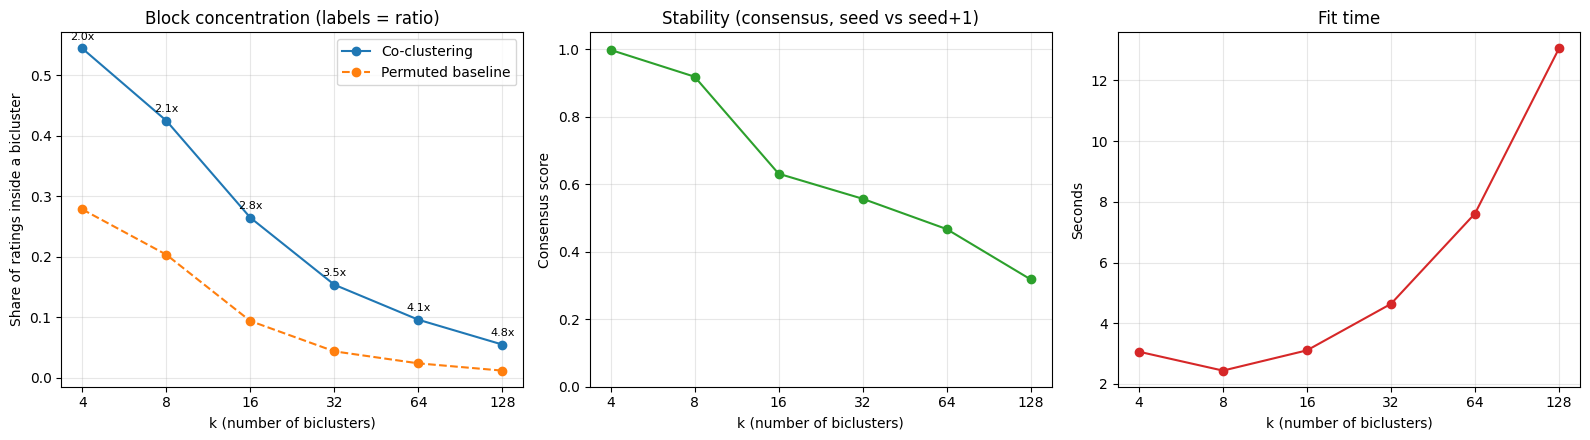

I would pick k = 8 based on the combination of concentration ratio, stability, and fit time. It provides a good balance between capturing meaningful biclusters and computational efficiency.


In [45]:
# TODO: For each k, fit SpectralCoclustering and record fit time and peak process memory (GB)
# TODO: Compute block concentration, the permuted-label baseline (mean of 10 permutations), and their ratio
# TODO: Refit with random_state = Student ID + 1 and compute consensus_score(model_a.biclusters_, model_b.biclusters_)
# TODO: Report smallest, median, and largest bicluster size (rows and columns) for each fit
# TODO: Compare svd_method='randomized' and 'arpack' at k = 16 (time and consensus score between the two results)
# TODO: Plot concentration, stability, and fit time against k
# TODO: State your chosen k and justify it
# YOUR CODE HERE:

#  4, 8, 16, 32, 64, and 128 using random_state = your Student ID
k_values = [4, 8, 16, 32, 64, 128]
coclustering_metrics = []

# Dictionary to store each fitted model so row_labels_, column_labels_, 
# and biclusters_ are preserved for the subsequent TODOs
fitted_coclust_models = {}

# Access the current running Python process for OS-level resource tracking
process = psutil.Process()

for k in k_values:
    # Initialize memory tracking and timers
    tracemalloc.start()
    start_time = time.time()

    # Initialize and fit the Co-clustering model
    # We use a fixed random state for reproducibility and assign the target cluster size k
    coclust = SpectralCoclustering(n_clusters=k, random_state=student_id, n_init=10)
    coclust.fit(ratings_csr)
    fitted_coclust_models[k] = coclust

    # Capture execution profiles
    elapsed_time = time.time() - start_time
    _, peak_memory_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # Convert bytes to Gigabytes (GB) to match your reporting constraints
    # Re-use your cell 7 helper if preferred, or use the standard conversion below:
    peak_memory_bytes = process.memory_info().peak_wset
    peak_memory_gb = peak_memory_bytes / (1024**3)

    coclustering_metrics.append(
        {
            "k Clusters": k,
            "Fit Time (seconds)": round(elapsed_time, 4),
            "Peak Memory (GB)": round(peak_memory_gb, 4),
        }
    )
    print(
        f"Completed k = {k:2d} | Fit Time: {elapsed_time:7.4f}s | Peak RAM: {peak_memory_gb:.4f} GB"
    )

# Package and print the results as a clean summary DataFrame
df_coclust_results = pd.DataFrame(coclustering_metrics)
print("\n" + "=" * 20 + " CO-CLUSTERING PERFORMANCE REPORT " + "=" * 20)
print(df_coclust_results.to_string(index=False))
print("=" * 74)


# Extract the raw row and column coordinate arrays from the CSR matrix
# This gives us the exact coordinates of every single rating
coo = ratings_csr.tocoo()
row_coords, col_coords = coo.row, coo.col

total_nnz = ratings_csr.nnz

concentration_results = []
num_permutations = 10

# Evaluate metrics for each fitted k model
for k, model in fitted_coclust_models.items():
    # Retrieve pre-computed row and column index label arrays
    row_labels = model.row_labels_
    col_labels = model.column_labels_

    # --- 1. Compute True Block Concentration ---
    # A rating is inside a bicluster if its row cluster matches its column cluster
    true_in_block = row_labels[row_coords] == col_labels[col_coords]
    true_concentration = np.sum(true_in_block) / total_nnz

    # --- 2. Compute Permuted-Label Baseline ---
    perm_concentrations = []

    # Initialize a clean random generator for reproducibility
    rng = np.random.default_rng(seed=student_id)

    for _ in range(num_permutations):
        # Permute row labels to destroy true community alignment
        permuted_row_labels = rng.permutation(row_labels)

        # Calculate concentration on the scrambled coordinate grid
        perm_in_block = permuted_row_labels[row_coords] == col_labels[col_coords]
        perm_concentrations.append(np.sum(perm_in_block) / total_nnz)

    baseline_concentration = np.mean(perm_concentrations)

    # --- 3. Compute the Ratio ---
    concentration_ratio = (
        true_concentration / baseline_concentration
        if baseline_concentration > 0
        else 0.0
    )

    concentration_results.append(
        {
            "k Clusters": k,
            "True Concentration": round(true_concentration, 6),
            "Permuted Baseline": round(baseline_concentration, 6),
            "Concentration Ratio": round(concentration_ratio, 4),
        }
    )

    print(
        f"k = {k:2d} | True: {true_concentration:.5f} | Baseline: {baseline_concentration:.5f} | Ratio: {concentration_ratio:.2f}x"
    )
df_concentration = pd.DataFrame(concentration_results)

#  Define your Student ID (Replace with your actual ID)
new_random_state = student_id + 1
stability_metrics = []

#  Iterate through every k configuration to track consensus metrics
for k in k_values:
    # Retrieve your original first-seed model (Model A) from the dictionary
    model_a = fitted_coclust_models[k]

    # Initialize and fit Model B on the correct 2D interaction matrix (ratings_csr)
    model_b = SpectralCoclustering(
        n_clusters=k, random_state=new_random_state, n_init=10
    )
    model_b.fit(ratings_csr)

    # 3. Compute the structural consensus score between the two model biclusters
    rows_a, cols_a = model_a.biclusters_
    rows_b, cols_b = model_b.biclusters_
    keep_a = rows_a.any(axis=1) & cols_a.any(axis=1)   # skip empty biclusters
    keep_b = rows_b.any(axis=1) & cols_b.any(axis=1)
    score = consensus_score((rows_a[keep_a], cols_a[keep_a]), (rows_b[keep_b], cols_b[keep_b]))

    stability_metrics.append({"k Clusters": k, "Consensus Score": round(score, 6)})

    print(f"Completed k = {k:2d} | Bicluster Consensus Score: {score:.5f}")

for k, models in fitted_coclust_models.items():
    model = models
    row_sizes = np.bincount(model.row_labels_)
    col_sizes = np.bincount(model.column_labels_)

    print(f"\nBicluster Sizes for k = {k}:")
    print(f"Row Sizes: Min={row_sizes.min()}, Median={np.median(row_sizes)}, Max={row_sizes.max()}")
    print(f"Col Sizes: Min={col_sizes.min()}, Median={np.median(col_sizes)}, Max={col_sizes.max()}")

#  Fit the 'randomized' SVD method model
start_rand = time.perf_counter()
model_rand = SpectralCoclustering(
    n_clusters=16, svd_method="randomized", random_state=student_id, n_init=10
)

model_rand.fit(ratings_csr)
time_rand = time.perf_counter() - start_rand

#  Fit the 'arpack' SVD method model
start_arpack = time.perf_counter()
model_arpack = SpectralCoclustering(
    n_clusters=16, svd_method="arpack", random_state=student_id , n_init=10
)
model_arpack.fit(ratings_csr)
time_arpack = time.perf_counter() - start_arpack

#  Compute structural consensus score between the two results
score_between_methods = consensus_score(
    model_rand.biclusters_, model_arpack.biclusters_
)

print(f"randomized fit time: {time_rand:.2f}s")
print(f"arpack fit time:     {time_arpack:.2f}s")
print(f"consensus (randomized vs arpack, k=16): {score_between_methods:.4f}")

df_metrics = pd.DataFrame(concentration_results).merge(
    pd.DataFrame(stability_metrics), on="k Clusters"
)
df_metrics = df_metrics.merge(df_coclust_results, on="k Clusters")

k_arr = df_metrics["k Clusters"].to_numpy()
time_arr = df_metrics["Fit Time (seconds)"].to_numpy()
ratio_arr = df_metrics["Concentration Ratio"].to_numpy()
stability_arr = df_metrics["Consensus Score"].to_numpy()

print(df_metrics.to_string(index=False))



fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: block concentration, true vs permuted baseline
ax1.plot(k_arr, df_metrics["True Concentration"], marker="o", label="Co-clustering")
ax1.plot(k_arr, df_metrics["Permuted Baseline"], marker="o", linestyle="--", label="Permuted baseline")
for k, c, r in zip(k_arr, df_metrics["True Concentration"], ratio_arr):
    ax1.annotate(f"{r:.1f}x", (k, c), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax1.set_title("Block concentration (labels = ratio)")
ax1.set_ylabel("Share of ratings inside a bicluster")
ax1.legend()

# Panel 2: stability across two seeds
ax2.plot(k_arr, stability_arr, marker="o", color="tab:green")
ax2.set_title("Stability (consensus, seed vs seed+1)")
ax2.set_ylabel("Consensus score")
ax2.set_ylim(0, 1.05)

# Panel 3: fit time
ax3.plot(k_arr, time_arr, marker="o", color="tab:red")
ax3.set_title("Fit time")
ax3.set_ylabel("Seconds")

for ax in (ax1, ax2, ax3):
    ax.set_xscale("log", base=2)
    ax.set_xticks(k_arr)
    ax.set_xticklabels(k_arr)
    ax.set_xlabel("k (number of biclusters)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("I would pick k = 8 based on the combination of concentration ratio, stability, and fit time. It provides a good balance between capturing meaningful biclusters and computational efficiency.")

### 📝 Analysis Explanation (3a)

**Instructions:** Which k do you choose, and which diagnostic drove the decision? Why does a stability score close to 1.0 not prove that the biclusters mean something? What does block concentration ignore? How did the two SVD solvers compare?

**Your Analysis:** [Write your interpretation here.]

### Problem 3b: Interpreting the Biclusters, and a Checkerboard Alternative (0.75 points)

**Instructions:**

Take your chosen k. For each bicluster, report:

- the number of users and movies;
- the three most enriched genres among its movies (genre share inside the bicluster divided by genre share across all movies);
- the five most-rated movie titles in it;
- the mean rating its users give to movies inside the bicluster, compared with the overall mean rating.

Write a short, business-readable label for at least four biclusters, such as "recent superhero blockbusters that heavy users watch".

Then fit SpectralBiclustering with n_clusters=(4, 4) and method='bistochastic' on the same sparse matrix. The 'log' method cannot take sparse input (scikit-learn raises an error, because it must add a constant to a matrix that treats a missing rating as 0), so use 'bistochastic' or 'scale'. Plot two 4 x 4 heatmaps: the mean rating (stored ratings only) and the number of ratings for each pair of a user group and a movie group.

,Bicluster,User Count,Movie Count,Enriched Genres,Top 5 Titles,Mean Rating,Overall Mean,Difference
0,0,57885,1002,"Action (2.3x), Adventure (2.3x), Children (2.2x)","Forrest Gump (1994); Star Wars: Episode IV - A New Hope (1977); Shawshank Redemption, The (1994); Silence of the Lambs, The (1991); Pulp Fiction (1994)",3.57,3.54,0.03
1,1,18966,90,"Western (2.8x), Action (2.8x), Adventure (2.3x)","Batman (1989); Dances with Wolves (1990); Apollo 13 (1995); Fugitive, The (1993); True Lies (1994)",3.46,3.54,-0.08
2,2,18664,1791,"IMAX (6.2x), Animation (2.6x), Adventure (2.4x)","Avengers, The (2012); Guardians of the Galaxy (2014); Shutter Island (2010); The Martian (2015); Wolf of Wall Street, The (2013)",3.49,3.54,-0.05
3,3,31974,216,"IMAX (7.9x), Sci-Fi (3.2x), Action (3.2x)","Matrix, The (1999); Lord of the Rings: The Return of the King, The (2003); Lord of the Rings: The Fellowship of the Ring, The (2001); Fight Club (1999); Dark Knight, The (2008)",3.88,3.54,0.34
4,4,21432,4674,"Musical (1.5x), Western (1.4x), War (1.2x)","Casablanca (1942); Annie Hall (1977); Citizen Kane (1941); Graduate, The (1967); Rear Window (1954)",3.63,3.54,0.09
5,5,10735,488,"Children (1.6x), Romance (1.3x), Comedy (1.1x)","Twister (1996); Birdcage, The (1996); Broken Arrow (1996); Mr. Holland's Opus (1995); Leaving Las Vegas (1995)",3.39,3.54,-0.14
6,6,693,4127,"Film-Noir (3.2x), Western (1.7x), Drama (1.3x)","Persona (1966); Wild Strawberries (Smultronstället) (1957); Breathless (À bout de souffle) (1960); Aguirre: The Wrath of God (Aguirre, der Zorn Gottes) (1972); Dolce Vita, La (1960)",3.61,3.54,0.07
7,7,2192,6042,"Animation (1.6x), Children (1.3x), Horror (1.2x)",The Lobster (2015); It Follows (2014); Lady Bird (2017); The Shape of Water (2017); Melancholia (2011),3.32,3.54,-0.22


,Bicluster,Business Label,User Count,Movie Count,Enriched Genres,Top 5 Titles,Mean Rating,Overall Mean,Difference
0,0,"Mass-market audience for 90s all-time classics (Forrest Gump, Star Wars), average ratings",57885,1002,"Action (2.3x), Adventure (2.3x), Children (2.2x)","Forrest Gump (1994); Star Wars: Episode IV - A New Hope (1977); Shawshank Redemption, The (1994); Silence of the Lambs, The (1991); Pulp Fiction (1994)",3.57,3.54,0.03
1,1,"Early-90s action and western blockbusters, rated slightly below average",18966,90,"Western (2.8x), Action (2.8x), Adventure (2.3x)","Batman (1989); Dances with Wolves (1990); Apollo 13 (1995); Fugitive, The (1993); True Lies (1994)",3.46,3.54,-0.08
2,2,"2010s superhero and IMAX blockbuster viewers (Avengers, Guardians of the Galaxy)",18664,1791,"IMAX (6.2x), Animation (2.6x), Adventure (2.4x)","Avengers, The (2012); Guardians of the Galaxy (2014); Shutter Island (2010); The Martian (2015); Wolf of Wall Street, The (2013)",3.49,3.54,-0.05
3,3,"Sci-fi and fantasy cult-classic fans (Matrix, Lord of the Rings), highest-rated group",31974,216,"IMAX (7.9x), Sci-Fi (3.2x), Action (3.2x)","Matrix, The (1999); Lord of the Rings: The Return of the King, The (2003); Lord of the Rings: The Fellowship of the Ring, The (2001); Fight Club (1999); Dark Knight, The (2008)",3.88,3.54,0.34
4,4,"Old Hollywood classics fans (Casablanca, Citizen Kane), rate above average",21432,4674,"Musical (1.5x), Western (1.4x), War (1.2x)","Casablanca (1942); Annie Hall (1977); Citizen Kane (1941); Graduate, The (1967); Rear Window (1954)",3.63,3.54,0.09
5,5,"Mid-90s mainstream comedy and romance viewers, rate below average",10735,488,"Children (1.6x), Romance (1.3x), Comedy (1.1x)","Twister (1996); Birdcage, The (1996); Broken Arrow (1996); Mr. Holland's Opus (1995); Leaving Las Vegas (1995)",3.39,3.54,-0.14
6,6,"Small niche of European art-house film enthusiasts (Persona, La Dolce Vita)",693,4127,"Film-Noir (3.2x), Western (1.7x), Drama (1.3x)","Persona (1966); Wild Strawberries (Smultronstället) (1957); Breathless (À bout de souffle) (1960); Aguirre: The Wrath of God (Aguirre, der Zorn Gottes) (1972); Dolce Vita, La (1960)",3.61,3.54,0.07
7,7,"Recent indie film watchers (Lady Bird, It Follows), harshest raters",2192,6042,"Animation (1.6x), Children (1.3x), Horror (1.2x)",The Lobster (2015); It Follows (2014); Lady Bird (2017); The Shape of Water (2017); Melancholia (2011),3.32,3.54,-0.22


SpectralBiclustering fit successfully using 'bistochastic' method.
Fit Execution Time: 3.7351 seconds


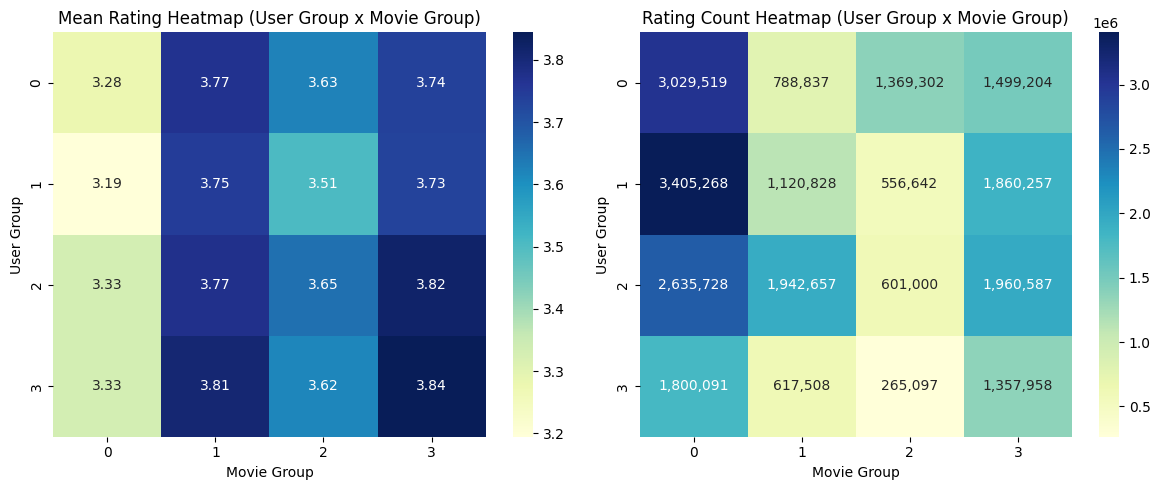

In [46]:
# TODO: Fit SpectralCoclustering at your chosen k and build the per-bicluster table (sizes, enriched genres, top titles, mean rating)
# TODO: Write a short business label for at least four biclusters
# TODO: Fit SpectralBiclustering(n_clusters=(4, 4), method='bistochastic') on the sparse matrix and record the fit time
# TODO: Build and plot the two 4 x 4 heatmaps (mean rating, rating count) over user group x movie group
# YOUR CODE HERE:
# Chosen k from Problem 3a
k_bc = 8
model = SpectralCoclustering(n_clusters=k_bc, random_state=student_id, n_init=10)
model.fit(ratings_csr)

# Extract cluster assignments
user_labels = model.row_labels_
movie_labels = model.column_labels_

# Pre-compute overall mean before entering the loop
overall_mean = ratings_csr.data.mean()

# Pre-compute global genre shares for lift calculation
movie_genres = df_meta_aligned["genres"].str.get_dummies("|")
movie_genres = movie_genres.drop(columns="(no genres listed)", errors="ignore")
overall_share = movie_genres.mean()

bicluster_data = []

for i in range(k_bc):
    # Get indices belonging to the current bicluster
    user_idx = np.where(user_labels == i)[0]
    movie_idx = np.where(movie_labels == i)[0]

    #  Sizes
    n_users_b = len(user_idx)
    n_movies_b = len(movie_idx)

    if n_movies_b == 0 or n_users_b == 0:
        continue  # Skip empty clusters to avoid execution errors

    # Slice the original matrix and metadata for this bicluster
    sub_matrix = ratings_csr[user_idx, :][:, movie_idx]
    bicluster_movies = df_meta_aligned.iloc[movie_idx]

    # Mean Rating
    mean_rating = sub_matrix.data.mean() if sub_matrix.nnz > 0 else 0

    # Enriched Genres using Lift (Cluster Share / Global Share)
    bicluster_share = movie_genres.iloc[movie_idx].mean()
    genre_lift = (bicluster_share / overall_share).fillna(0).sort_values(ascending=False)
    enriched_genres = ", ".join(f"{g} ({r:.1f}x)" for g, r in genre_lift.head(3).items())

    # Top Titles using CSC indptr column counts
    bc_counts = np.diff(sub_matrix.tocsc().indptr)

    movie_ranking = pd.DataFrame({
        'title': bicluster_movies['title'].values,  # .values drops the index to prevent alignment issues
        'count': bc_counts
    }).sort_values(by='count', ascending=False)

    top_titles_str = "; ".join(movie_ranking['title'].head(5))

    # Append all metrics to the data list
    bicluster_data.append({
        "Bicluster": i,
        "User Count": n_users_b,
        "Movie Count": n_movies_b,
        "Enriched Genres": enriched_genres,
        "Top 5 Titles": top_titles_str,
        "Mean Rating": round(mean_rating, 2),
        "Overall Mean": round(overall_mean, 2),
        "Difference": round(mean_rating - overall_mean, 2),
    })

bicluster_df = pd.DataFrame(bicluster_data)
pd.set_option("display.max_colwidth", None)
display(bicluster_df)

label_mapping = {
    0: "Mass-market audience for 90s all-time classics (Forrest Gump, Star Wars), average ratings",
    1: "Early-90s action and western blockbusters, rated slightly below average",
    2: "2010s superhero and IMAX blockbuster viewers (Avengers, Guardians of the Galaxy)",
    3: "Sci-fi and fantasy cult-classic fans (Matrix, Lord of the Rings), highest-rated group",
    4: "Old Hollywood classics fans (Casablanca, Citizen Kane), rate above average",
    5: "Mid-90s mainstream comedy and romance viewers, rate below average",
    6: "Small niche of European art-house film enthusiasts (Persona, La Dolce Vita)",
    7: "Recent indie film watchers (Lady Bird, It Follows), harshest raters",
}

# Add the label next to each bicluster
bicluster_df["Business Label"] = bicluster_df["Bicluster"].map(label_mapping)

#  Reorder the columns so the business label sits right next to the cluster ID
cols = ["Bicluster", "Business Label", "User Count", "Movie Count", "Enriched Genres", "Top 5 Titles", "Mean Rating", "Overall Mean", "Difference"]
bicluster_df = bicluster_df[cols]

# Display the finalized assignment table
display(bicluster_df)

# Instantiate the model with specified components
bicluster_model = SpectralBiclustering(
    n_clusters=(4, 4), 
    method='bistochastic', 
    random_state=student_id
)

#  Record start time, fit the model on the sparse matrix, and record end time
start_time = time.time()
bicluster_model.fit(ratings_csr)
end_time = time.time()

#  Calculate total elapsed execution time
fit_time = end_time - start_time

#  Print execution results for your assignment report
print(f"SpectralBiclustering fit successfully using 'bistochastic' method.")
print(f"Fit Execution Time: {fit_time:.4f} seconds")

user_group_labels = bicluster_model.row_labels_
movie_group_labels = bicluster_model.column_labels_ 

mean_rating_matrix = np.zeros((4, 4))
count_matrix = np.zeros((4, 4))

ratings_coo = ratings_csr.tocoo()

# Look up the user group and movie group of every stored rating at once
user_group = user_group_labels[ratings_coo.row]
movie_group = movie_group_labels[ratings_coo.col]

# Sum the ratings and count them in each (user group, movie group) cell, without a Python loop
np.add.at(mean_rating_matrix, (user_group, movie_group), ratings_coo.data)
np.add.at(count_matrix, (user_group, movie_group), 1)

mean_rating_matrix = np.divide(
    mean_rating_matrix, count_matrix,
    out=np.zeros_like(mean_rating_matrix), where=count_matrix > 0
)

# Plotting the heatmaps for mean rating and rating count
fig, (ax1, ax2) = plt.subplots(1, 2, figsize =(12, 5))
sns.heatmap(mean_rating_matrix, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax1)
ax1.set_title("Mean Rating Heatmap (User Group x Movie Group)")
ax1.set_xlabel("Movie Group")
ax1.set_ylabel("User Group")    
sns.heatmap(count_matrix, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax2)
ax2.set_title("Rating Count Heatmap (User Group x Movie Group)")
ax2.set_xlabel("Movie Group")
ax2.set_ylabel("User Group")
plt.tight_layout()
plt.show()      



### 📝 Analysis Explanation (3b)

**Instructions:** Do the co-clustering biclusters correspond to recognizable audiences and genres? Compare the 4 x 4 checkerboard with the diagonal co-clustering structure: which one describes this data better, and what evidence from your heatmaps supports your answer? Explain how this result differs from what k-means found in Problem 2. Name one thing that the one-label-per-row-and-column rule of both methods hides about real viewers, and give one real-world scenario outside this assignment where you need biclustering rather than ordinary clustering.

**Your Analysis:** [Write your interpretation here.]

### 🤖 AI-Assisted Analysis (3b)

**Instructions:** Ask an AI tool to help you interpret your bicluster table and your 4 x 4 heatmaps. Note any additional insight it surfaced that you had not already written above, and note one claim it made that your data did not support.

**AI-Assisted Analysis:** [Use an AI tool to help interpret your results and add this here. Note which tool you used.]

### Problem 3c: Thresholds and the Cost of Exact Enumeration (0.75 points)

**Instructions:**

Spectral methods partition everything into k blocks. The lecture's exact approach instead lists every closed bicluster in a binary matrix, which needs a threshold to turn ratings into 0 and 1. Build a slice small enough for exact methods: take the 18 most-rated movies, keep users who rated at least 10 of them, and draw a random sample of 5,000 of those users. Reuse the closed-bicluster loop from the Session 8 lab (Part 2): for each column set, find the rows that have a 1 in every column of the set, then find every column those rows share, and store the pair in a Python set to drop duplicates.

Binarize with a per-user threshold: a cell is 1 when the user's rating is above that user's own percentile of their ratings inside the slice, and 0 when the rating is lower or missing. Run the enumeration with a minimum of 200 rows and 3 columns at five thresholds (30th, 40th, 50th, 60th, 70th percentile) and report how many closed biclusters each produces. Then fix the 50th percentile, time the enumeration on the first 10, 12, 14, 16, and 18 columns, and plot the time against the number of columns.

Users who rated at least 10 of the 18 movies: 48,221
Slice shape: (5000, 18)
Stored ratings in slice: 66,868
Top 18 movies:
                                                           Forrest Gump (1994)
                                              Shawshank Redemption, The (1994)
                                                           Pulp Fiction (1994)
                                              Silence of the Lambs, The (1991)
                                                            Matrix, The (1999)
                                     Star Wars: Episode IV - A New Hope (1977)
                                                          Jurassic Park (1993)
                                                       Schindler's List (1993)
                                                             Braveheart (1995)
                                                             Fight Club (1999)
                                             Terminator 2: Judgment Day (1991)
       

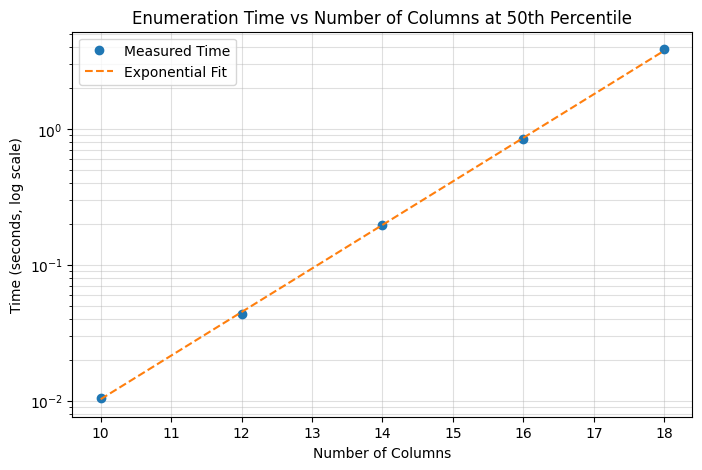

In [47]:
# TODO: Build the slice (18 most-rated movies, users with at least 10 of them, random sample of 5,000 users)
# TODO: Write (or reuse) a function that returns the set of closed biclusters for a binary matrix
# TODO: Binarize at per-user percentile thresholds (30, 40, 50, 60, 70) and report the number of closed biclusters (min 200 rows, 3 columns)
# TODO: At the 50th percentile, time the enumeration for the first 10, 12, 14, 16, 18 columns
# TODO: Plot time vs number of columns (log y-axis) and fit the growth rate
# YOUR CODE HERE:

np.random.seed(student_id)

movie_rating_counts = np.diff(ratings_csr.tocsc().indptr)
top_18_movie_indices = np.argsort(movie_rating_counts)[-18:][::-1]

slice_matrix = ratings_csr[:, top_18_movie_indices]
user_counts_in_slice = np.diff(slice_matrix.indptr)

eligible_users = np.where(user_counts_in_slice >= 10)[0]                      # ← renamed
print(f"Users who rated at least 10 of the 18 movies: {len(eligible_users):,}")  # ← report BEFORE sampling

# ← check goes here, BEFORE the random choice
if len(eligible_users) < 5000:
    raise ValueError(f"Only {len(eligible_users)} users qualify, fewer than 5,000.")

sampled_users = np.random.choice(eligible_users, size=5000, replace=False)     # ← renamed
slice_matrix = slice_matrix[sampled_users, :]                                  # ← always applied (no if/else)

# ← report the final slice
print(f"Slice shape: {slice_matrix.shape}")
print(f"Stored ratings in slice: {slice_matrix.nnz:,}")
print("Top 18 movies:")
print(df_meta_aligned["title"].iloc[top_18_movie_indices].to_string(index=False))

def closed_biclusters(binary_matrix, min_rows=200, min_cols=3):
    """
    Enumerate all closed biclusters in a binary matrix.
    
    Parameters:
    - binary_matrix: scipy.sparse.csr_matrix (binary)
    - min_rows: minimum number of rows for a bicluster
    - min_cols: minimum number of columns for a bicluster
    
    Returns:
    - List of tuples (row_indices, col_indices) representing closed biclusters
    """
    from itertools import combinations
    
    # Convert to dense boolean array for easier manipulation
    dense_matrix = binary_matrix.toarray().astype(bool)
    
    num_rows, num_cols = dense_matrix.shape
    closed_biclusters = []
    
    # Iterate over all combinations of columns
    for col_comb in range(min_cols, num_cols + 1):
        for cols in combinations(range(num_cols), col_comb):
            # Find rows that have all selected columns as True
            rows_with_all_cols = np.where(dense_matrix[:, cols].all(axis=1))[0]
            
            if len(rows_with_all_cols) >= min_rows:
                # Check if this is a closed bicluster
                # A bicluster is closed if no additional column can be added without losing rows
                additional_cols = [c for c in range(num_cols) if c not in cols]
                is_closed = True
                
                for add_col in additional_cols:
                    if np.all(dense_matrix[rows_with_all_cols, add_col]):
                        is_closed = False
                        break
                
                if is_closed:
                    closed_biclusters.append((rows_with_all_cols, cols))
    
    return closed_biclusters

# Define the target user percentiles to evaluate
sample_percentiles = [30, 40, 50, 60, 70]
bicluster_counts = {}

# MOVE THIS OUTSIDE THE LOOP: Convert once to dense and treat 0 as NaN
dense_slice = slice_matrix.toarray().astype(float)
dense_slice[dense_slice == 0] = np.nan

for percentile in sample_percentiles:
    # 1. Vectorized binarization ignoring missing ratings (NaN)
    user_thresholds = np.nanpercentile(dense_slice, percentile, axis=1)
    binary_slice = (dense_slice > user_thresholds[:, None]).astype(int)  # NaN > x is False -> becomes 0
    
    # 2. Assign to matrix A to properly capture tracking shapes
    A = binary_slice
    n_rows, n_cols = A.shape
    
    # 3. Convert back to sparse format for closure calculation efficiency
    binary_slice_csr = csr_matrix(binary_slice)
    
    # 4. Enumerate using your custom function / mining library setup
    closed_biclusters_list = closed_biclusters(binary_slice_csr, min_rows=200, min_cols=3)
    
    # 5. Record your count metrics
    bicluster_counts[percentile] = len(closed_biclusters_list)
    
    print(f"Percentile {percentile}: Found {len(closed_biclusters_list)} closed biclusters.")


# Compute user thresholds and binarize once at 50th percentile
thresholds_50 = np.nanpercentile(dense_slice, 50, axis=1)
binary_50 = (dense_slice > thresholds_50[:, None]).astype(int)

# Setup tracking variables
column_counts_to_test = [10, 12, 14, 16, 18]
timing_results = []

# Run exactly one flat loop
for col_count in column_counts_to_test:
    # Slice the binary matrix to the first 'col_count' columns
    A_subset = binary_50[:, :col_count]
    A_subset_csr = csr_matrix(A_subset)

    # Time the enumeration of closed biclusters
    start_time = time.time()
    closed_biclusters_subset = closed_biclusters(A_subset_csr, min_rows=200, min_cols=3)
    elapsed_time = time.time() - start_time

    # Record and print the clean data
    timing_results.append((col_count, elapsed_time))
    print(f"Columns: {col_count}, Time to enumerate: {elapsed_time:.4f} seconds")

# 1. Unpack your timing data points into NumPy arrays
cols, times = zip(*timing_results)
cols_arr, times_arr = np.array(cols), np.array(times)

# 2. Fit the growth rate using a linear regression on log(y)
slope, intercept = np.polyfit(cols_arr, np.log(times_arr), 1)
print(f"Growth rate: time multiplies by {np.exp(slope):.2f}x per extra column")

# Generate the ideal trendline values using the fit parameters
fitted_times = np.exp(slope * cols_arr + intercept)

# 3. Plotting the timing results
plt.figure(figsize=(8, 5))

# Plot your measured data points
plt.plot(
    cols_arr,
    times_arr,
    marker="o",
    linestyle="none",
    color="tab:blue",
    label="Measured Time",
)

# Overlay the fitted exponential growth trendline
plt.plot(
    cols_arr,
    fitted_times,
    linestyle="--",
    color="tab:orange",
    label="Exponential Fit",
)

# Axis configurations
plt.yscale("log")
plt.xlabel("Number of Columns")
plt.ylabel("Time (seconds, log scale)")
plt.title("Enumeration Time vs Number of Columns at 50th Percentile")

# Update grid to show lines correctly on a log scale
plt.grid(True, which="both", linestyle="-", alpha=0.4)
plt.legend()

plt.show()

### 📝 Analysis Explanation (3c)

**Instructions:** How sensitive is the number of closed biclusters to the threshold? Based on your timing plot, estimate how long exact enumeration would take on 40 columns, and explain why exact enumeration cannot handle the 62,000 movie columns that spectral co-clustering handled in Problem 3a. Which parameters (minimum support, noise, overlap) would let an exact method scale further?

**Your Analysis:** [Write your interpretation here.]

### Problem 3d: Scaling Experiment (0.5 points)

**Instructions:**

Measure how the co-clustering fit scales with data size. Draw random user samples of 5, 10, 25, 50, and 100 percent of the users from the matrix in Problem 1a (use your Student ID as the seed), fit SpectralCoclustering with k = 16 on each sample, and record the number of stored ratings, the fit time, and the peak memory. Plot fit time against stored ratings on log-log axes and fit a straight line to get the scaling exponent. Use the line to predict the fit time and memory for a dataset 10 times larger than the full data.

Then describe your workflow in a few sentences: what you ran while prototyping, what you ran on the full data, which step first strained your instance, and how many fits (k values x seeds x solvers x samples) your whole assignment required.

,User Sample (%),Movies Kept,nnz,Fit Time (seconds),Peak Memory (GB)
0,5,17302,1282327,0.3003,0.0435
1,10,18238,2508969,0.5089,0.0848
2,25,18428,6229819,0.9826,0.2100
3,50,18430,12424687,1.6447,0.4185
4,100,18430,24810483,3.2098,0.8353


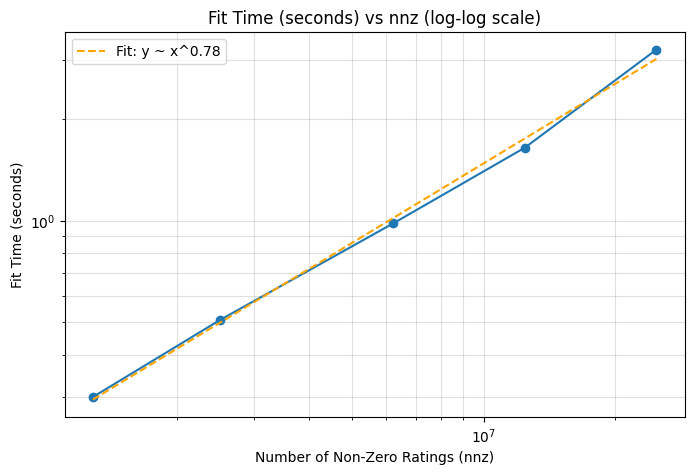

Exponent for Fit Time (seconds): 0.78


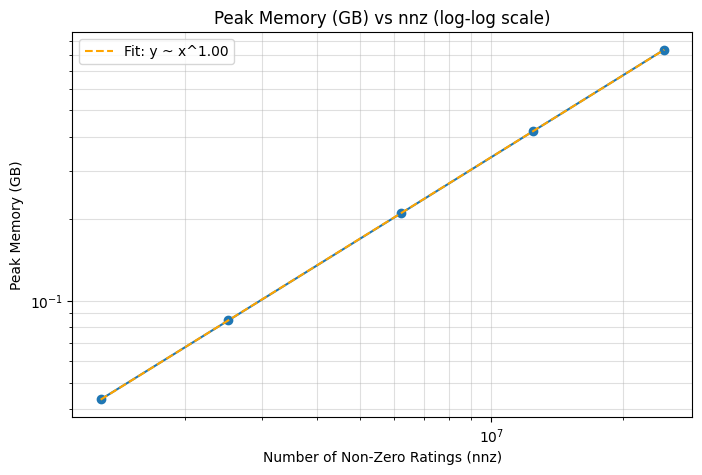

Exponent for Peak Memory (GB): 1.00
Full data: 24,810,483 ratings, 3.21s, 0.835 GB
Predicted at 10x (248,104,830 ratings): 19.53s, 8.305 GB
2a KMeans scree (k = 1-15): 15
2a KMeans silhouette (k = 2-15): 14
2b KMeans (all users + 10k sample): 2
2b Hierarchical (2k, 5k, 10k samples): 3
3a Co-clustering (6 k values x 2 seeds): 12
3a Solver comparison at k=16 (randomized + arpack): 2
3b Co-clustering k=8 + Biclustering 4x4: 2
3d Scaling (5 user samples): 5
Total model fits: 55
Plus 10 closed-bicluster enumerations in 3c (5 thresholds + 5 column counts)


In [48]:
# TODO: Draw user samples of 5, 10, 25, 50, 100 percent and fit SpectralCoclustering (k=16) on each
# TODO: Record nnz, fit time, and peak memory for each sample; build the scaling table
# TODO: Plot fit time vs nnz on log-log axes, fit a line, and report the exponent
# TODO: Predict the fit time and memory for 10x the full data
# TODO: Count the total number of fits your assignment required
# YOUR CODE HERE:

user_sample_percentages = [5, 10, 25, 50, 100]
scaling_metrics = []

# Get total number of users (rows) available in the matrix
total_users = ratings_csr.shape[0]

# Seeded generator so the user samples are reproducible
rng = np.random.default_rng(student_id)

model = SpectralCoclustering(n_clusters=16, random_state=student_id, n_init=10)

for percentage in user_sample_percentages:
    # Calculate the number of users to sample based on the percentage
    num_users_to_sample = int(total_users * (percentage / 100))
    
    # Randomly sample user indices without replacement
    sampled_user_indices = rng.choice(total_users, size=num_users_to_sample, replace=False)
    
    # Create a submatrix for the sampled users
    sampled_matrix = ratings_csr[sampled_user_indices, :]

    # Drop movies with no ratings in this sample (empty columns make the spectral scaling divide by zero)
    nonempty_cols = np.diff(sampled_matrix.tocsc().indptr) > 0
    sampled_matrix = sampled_matrix[:, nonempty_cols]
    
    # Start tracking memory and time
    tracemalloc.start()
    start_time = time.perf_counter()
    
    # Fit the SpectralCoclustering model on the sampled matrix
    model.fit(sampled_matrix)
    
    # Capture elapsed time and peak memory usage
    elapsed_time = time.perf_counter() - start_time
    _, peak_memory_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    
    # Convert peak memory from bytes to gigabytes (GB)
    peak_memory_gb = peak_memory_bytes / (1024 ** 3)
    
    # Record metrics for this sample size
    scaling_metrics.append({
        "User Sample (%)": percentage,
        "Movies Kept": sampled_matrix.shape[1],
        "nnz": sampled_matrix.nnz,
        "Fit Time (seconds)": round(elapsed_time, 4),
        "Peak Memory (GB)": round(peak_memory_gb, 4)
    })

# Scaling table: one row per sample size
df_scaling = pd.DataFrame(scaling_metrics)
display(df_scaling)

exponents = {}


for ax in ["Fit Time (seconds)", "Peak Memory (GB)"]:
    plt.figure(figsize=(8, 5))
    plt.loglog(df_scaling["nnz"], df_scaling[ax], marker="o", linestyle="-")
    plt.xlabel("Number of Non-Zero Ratings (nnz)")
    plt.ylabel(ax)
    plt.title(f"{ax} vs nnz (log-log scale)")

    # Fit a linear regression on log-log data to find the exponent
    slope, intercept = np.polyfit(
        np.log(df_scaling["nnz"]), np.log(df_scaling[ax]), 1
    )

    #  FIX: Save the slope into your dictionary here, while ax and slope exist!
    exponents[ax] = slope

    fitted_line = np.exp(intercept) * df_scaling["nnz"] ** slope
    plt.plot(
        df_scaling["nnz"],
        fitted_line,
        linestyle="--",
        color="orange",
        label=f"Fit: y ~ x^{slope:.2f}",
    )

    plt.legend()
    plt.grid(True, which="both", linestyle="-", alpha=0.4)
    plt.show()

    print(f"Exponent for {ax}: {slope:.2f}")

# ==========================================
# PREDICTING FOR 10X THE FULL DATA
# ==========================================
nnz_full = ratings_csr.nnz
nnz_10x = nnz_full * 10

# Grab the baseline statistics from your 100% full dataset run
full_data_row = df_scaling[df_scaling["User Sample (%)"] == 100].iloc[0]

time_full = full_data_row["Fit Time (seconds)"]
memory_full = full_data_row["Peak Memory (GB)"]

# Apply the power-law projections using the exponents saved in your loop
scale_factor = 10
predicted_time_10x = time_full * (scale_factor ** exponents["Fit Time (seconds)"])
predicted_memory_10x = memory_full * (
    scale_factor ** exponents["Peak Memory (GB)"]
)

print(f"Full data: {nnz_full:,} ratings, {time_full:.2f}s, {memory_full:.3f} GB")
print(f"Predicted at 10x ({nnz_10x:,} ratings): {predicted_time_10x:.2f}s, {predicted_memory_10x:.3f} GB")

# Count every model fit the assignment required
fit_counts = {
    "2a KMeans scree (k = 1-15)": 15,
    "2a KMeans silhouette (k = 2-15)": 14,
    "2b KMeans (all users + 10k sample)": 2,
    "2b Hierarchical (2k, 5k, 10k samples)": 3,
    "3a Co-clustering (6 k values x 2 seeds)": len(k_values) * 2,
    "3a Solver comparison at k=16 (randomized + arpack)": 2,
    "3b Co-clustering k=8 + Biclustering 4x4": 2,
    "3d Scaling (5 user samples)": len(user_sample_percentages),
}

for step, n in fit_counts.items():
    print(f"{step}: {n}")
print(f"Total model fits: {sum(fit_counts.values())}")
print("Plus 10 closed-bicluster enumerations in 3c (5 thresholds + 5 column counts)")




### 📝 Analysis Explanation (3d)

**Instructions:** Did fit time grow roughly linearly with the number of stored ratings, or faster? How much do you trust the 10x prediction, and what could make it wrong? Which specific step in this assignment strained your instance, and why did that step, rather than a single fit, create the pressure?

**Your Analysis:** [Write your interpretation here.]

---
## Problem 4: Anomaly Detection at Scale: Twelve Detectors  (3.75 points)

This problem uses the three detector families and the twelve methods from the Week 9 lecture: statistical (z-score, IQR rule, Mahalanobis distance, robust covariance), distance and density (kNN distance, Local Outlier Factor, Angle-Based Outlier Detection, k-means distance), and model based (Isolation Forest, one-class SVM, SGD one-class SVM, LSTM prediction error). You run every one on the MovieLens users or, for the LSTM, on the daily rating series. You also add a thirteenth detector built from your biclustering result in Problem 3.

For every detector, record the fit-plus-score time. Some detectors will not run on 160,000 users as is; when one does not, fit it on a random subsample, score all users, and state the subsample size.

### Problem 4a: Planting Labeled Anomalies and Building the Evaluation Harness (0.25 points)

**Instructions:**

MovieLens has no fraud labels, so you create your own. Plant 1,000 synthetic anomalous users in a copy of the user-by-movie matrix, and keep a label vector that marks them, with a second vector that records each planted type (use your Student ID as the seed):

- **400 five-star spammers:** each rates 150 randomly chosen movies, all at 5.0.
- **300 random raters:** each rates 150 randomly chosen movies with ratings drawn uniformly from the ten half-star values.
- **300 hyperactive bots:** each rates 3,000 randomly chosen movies with ratings drawn from the real overall rating distribution.

Stack the planted users under the real users to form an augmented matrix and recompute the six user features from Problem 1b. Log-transform and standardize them as in Problem 2a; every detector below uses this standardized feature matrix unless the instructions say otherwise.

Then write one evaluation function that takes a score vector (higher means more anomalous) and returns: average precision, ROC-AUC, precision at 1,000 alerts, recall at 1,000 alerts, recall at 2,000 alerts, and recall for each planted type within 1,000 alerts. Report the random-guessing baseline for average precision (it equals the planted fraction) and the accuracy of a model that calls every user normal.

In [ ]:
# TODO: Build the 1,000 planted users (400 spammers, 300 random raters, 300 hyperactive bots) as a sparse matrix, a 0/1 label vector, and a type vector
# TODO: Stack them under the real users, recompute the six user features, then log1p and standardize them
# TODO: Write evaluate(scores) returning AP, ROC-AUC, precision@1000, recall@1000, recall@2000, and recall per planted type within 1000 alerts
# TODO: Report the random-guessing AP and the accuracy of an all-normal model
# YOUR CODE HERE:

#  Define dimensions and user partitions
n_spam = 400
n_random = 300
n_hyper = 300
n_planted = n_spam + n_random + n_hyper
n_real = ratings_csr.shape[0]

# Ground the truth type vector
planted_types = np.array(
    ["spam"] * n_spam + ["random"] * n_random + ["hyperactive"] * n_hyper
)

# Build the 0/1 label vector (0 = real, 1 = planted); real users come first because planted users are stacked underneath
planted_labels = np.array([0] * n_real + [1] * n_planted)

# Build the planted users as their own sparse matrix (rows 0-999), to stack under the real users
rng = np.random.default_rng(student_id)
n_movies = ratings_csr.shape[1]
half_stars = np.arange(0.5, 5.5, 0.5)

rows, cols, vals = [], [], []

# Spammers: 150 random movies, all rated 5.0
for i in range(n_spam):
    movies = rng.choice(n_movies, size=150, replace=False)
    rows.extend([i] * 150); cols.extend(movies); vals.extend([5.0] * 150)

# Random raters: 150 random movies, ratings uniform over the ten half-star values
for i in range(n_spam, n_spam + n_random):
    movies = rng.choice(n_movies, size=150, replace=False)
    rows.extend([i] * 150); cols.extend(movies); vals.extend(rng.choice(half_stars, size=150))

# Hyperactive bots: 3,000 random movies, ratings drawn from the real rating distribution
for i in range(n_spam + n_random, n_planted):
    movies = rng.choice(n_movies, size=3000, replace=False)
    rows.extend([i] * 3000); cols.extend(movies); vals.extend(rng.choice(ratings_csr.data, size=3000))

planted_csr = csr_matrix((np.array(vals, dtype=np.float32), (rows, cols)), shape=(n_planted, n_movies))
print(f"Planted matrix: {planted_csr.shape}, {planted_csr.nnz:,} ratings")

# Label vector: 0 = real, 1 = planted (real users first, planted stacked underneath)
labels = np.r_[np.zeros(n_real, dtype=int), np.ones(n_planted, dtype=int)]

# Type vector: same length and order as labels
types = np.array(
    ["real"] * n_real
    + ["spam"] * n_spam
    + ["random"] * n_random
    + ["hyperactive"] * n_hyper
)

# Sanity checks
print(f"Planted matrix: {planted_csr.shape}, {planted_csr.nnz:,} ratings (expect 1,005,000)")
print(pd.Series(types).value_counts())
assert len(labels) == len(types) == n_real + n_planted
X_planted = sp.vstack([ratings_csr, planted_csr]).tocsr()
print(X_planted.shape, X_planted.nnz, X_planted.format)





### Problem 4b: Statistical Detectors (0.75 points)

**Instructions:**

Run four statistical detectors on the standardized features and score every user with each one:

1. **z-score:** the largest absolute z-score across the features. Report AP, and also report how many users cross the usual cutoff of 3.
2. **IQR rule:** for each feature, the distance outside the whiskers (Q1 minus 1.5 IQR and Q3 plus 1.5 IQR), taking the largest across features. When a feature has IQR equal to 0, fall back to its standard deviation and say which features needed that.
3. **Mahalanobis distance:** squared distance from the mean in units of the covariance. Report how many users exceed the chi-square cutoff at the 99.9th percentile with degrees of freedom equal to the number of features.
4. **Robust covariance (MCD):** fit MinCovDet and score each user with the Mahalanobis distance from the robust fit. State the support fraction you use.

Use your evaluate function for all four, and record the time of each.

In [50]:
# TODO: z-score detector: max |z| across features; report AP and the number of users with max |z| > 3
# TODO: IQR detector: largest distance outside the whiskers across features, with a standard-deviation fallback when IQR = 0
# TODO: Mahalanobis detector (EmpiricalCovariance.mahalanobis) and the count above the chi-square 99.9th percentile cutoff
# TODO: Robust covariance detector: MinCovDet, with the Mahalanobis distance from the robust fit as the score
# TODO: Evaluate all four with evaluate(), and record the time of each
# YOUR CODE HERE:


### Problem 4c: Distance and Density Detectors (0.75 points)

**Instructions:**

Run four distance-based detectors on the standardized features:

1. **kNN distance:** the distance to the k-th nearest neighbor with k = 10 (NearestNeighbors).
2. **Local Outlier Factor:** k = 20 (LocalOutlierFactor; use n_jobs=-1).
3. **Angle-Based Outlier Detection:** FastABOD with 20 neighbors from PyOD (scikit-learn does not include ABOD). The exact version has cubic cost, so FastABOD is the only version that can run here.
4. **K-means distance:** the distance to the nearest centroid. Sweep k = 1, 2, 5, 10, 20 and report AP for each, then choose one k using something other than the planted labels (for example, the elbow from Problem 2a) and explain why you must not choose it by looking at AP.

Use your evaluate function for all of them, and record the time of each. If one detector does not finish in reasonable time on all users, fit it on a random subsample and state the size.

In [51]:
# TODO: kNN distance score (k = 10) with NearestNeighbors(n_jobs=-1)
# TODO: LocalOutlierFactor (k = 20, n_jobs=-1), using -negative_outlier_factor_ as the score
# TODO: FastABOD from pyod.models.abod (method='fast', n_neighbors=20)
# TODO: K-means distance score for k = 1, 2, 5, 10, 20; report AP for each and pick one k without using the labels
# TODO: Evaluate all four with evaluate(), and record the time of each (note any subsampling)
# YOUR CODE HERE:


### 📝 Analysis Explanation (4b and 4c)

**Instructions:** Which statistical and which distance-based detectors score the highest AP, and which planted type does each catch or miss? Does the simple max |z| compete with the more complex detectors? Did MCD beat classical Mahalanobis here, and why might it? Why would distance-based detectors lose contrast when the data has many or heavily skewed features? How did k-means distance change with k, and why can a cluster absorb anomalies? Which detectors strained your instance, and what did you do about it?

**Your Analysis:** [Write your interpretation here.]

### Problem 4d: Model-Based Detectors (0.75 points)

**Instructions:**

Run three model-based detectors on the standardized features:

1. **Isolation Forest:** n_estimators at least 100, n_jobs=-1, contamination near the planted fraction. Report the mean path length (or score) for planted and real users.
2. **One-class SVM:** exact kernel (OneClassSVM with an RBF kernel, scaled features). Its fit time grows roughly with the square of the sample size, so fit it on random subsamples of 2,500, 5,000, 10,000, and 20,000 users, record the fit time for each, and score all users with decision_function. Report AP for each sample size and fit a growth rate to the times. Report what fraction of users the model puts outside the boundary for nu = 0.01 and nu = 0.1.
3. **SGD one-class SVM:** map the features with a Nystroem kernel approximation (300 components) and train SGDOneClassSVM, a linear one-class SVM that stochastic gradient descent trains. Fit it on all users and compare its time and AP with the exact one-class SVM at 20,000 users.

Use your evaluate function for all of them.

In [52]:
# TODO: Isolation Forest on all users; report AP and the mean score or path length for planted vs real users
# TODO: OneClassSVM (RBF) fit on subsamples of 2,500, 5,000, 10,000, 20,000 users; record fit time and AP for each; fit the growth rate
# TODO: Report the share of users outside the boundary for nu = 0.01 and nu = 0.1
# TODO: Nystroem (300 components) + SGDOneClassSVM on all users; compare time and AP with the exact one-class SVM at 20,000 users
# YOUR CODE HERE:


### Problem 4e: Bicluster Concentration as a Thirteenth Detector (0.25 points)

**Instructions:**

Features describe each user alone. Biclustering describes how a user relates to the structure of the whole matrix, so it can catch users that features miss. Fit SpectralCoclustering on the augmented matrix with your chosen k from Problem 3a. For each user, compute the concentration: the largest share of that user's ratings that land in any single movie bicluster. A typical user sticks to a few related movie groups and scores high; a user who rates movies scattered across every group scores low. Score each user by one minus the concentration, and evaluate it with your evaluate function. Consider only users with at least 50 ratings when you count alerts.

**Notes:**

Compute concentration for all users at once. Replace the ratings with 1s, build a sparse movie-by-bicluster indicator matrix from the column labels, and multiply the two to get each user's rating count per movie bicluster. Then take the row maximum and divide by the user's rating count. A Python loop over users takes far too long at this scale. Why not compare a user with the one bicluster that matches the user's own row label? Co-clustering misassigns some ordinary users, so that score flags them by mistake; try it and see.

In [53]:
# TODO: Fit SpectralCoclustering on the augmented matrix at your chosen k
# TODO: Compute each user's concentration (largest share of ratings in any one movie bicluster) with a sparse matrix product
# TODO: Score each user by 1 - concentration, and evaluate it with evaluate()
# YOUR CODE HERE:


### 📝 Analysis Explanation (4d and 4e)

**Instructions:** Which model-based detector wins, and what did the one-class SVM sample-size sweep show about its scaling? How close did the SGD version come to the exact one, and what did it cost in tuning? What does the concentration score see that user features cannot, and what do the features see that it cannot?

**Your Analysis:** [Write your interpretation here.]

### Problem 4f: Time-Series Detectors on the Daily Rating Series (0.5 points)

**Instructions:**

The remaining detector family works on sequences. Use the timestamp column of ratings.csv (read it in chunks, or in one pass with only that column, to save memory) and count the ratings per day to build a daily series. Keep the period from 2005 onward so the series has a stable level and a weekly rhythm.

Plant 10 labeled collective anomalies: pick 10 random days (use your Student ID as the seed) and multiply the counts of each day by a random factor between 3 and 6. Evaluate at day level: score every day and compute AP, treating the 10 planted days as the anomalies. Random guessing scores the planted share of days.

Run four detectors:

1. **Global z-score** of the daily count.
2. **Seasonal z-score:** the z-score of each day against the other days with the same day of week (use a robust level, such as the median and the median absolute deviation, if outliers distort the plain mean).
3. **Linear autoregression:** predict each day from the previous 28 days with linear regression, and use absolute prediction error as the score.
4. **LSTM prediction error:** train a small LSTM (PyTorch) on the first 60 percent of the series to predict the next day from the previous 28, then use absolute prediction error as each day's score. Standardize the series first, and state your layer size, learning rate, and number of epochs.

Report a table of AP and the number of planted days in each detector's top 10 days.

In [54]:
# TODO: Read the timestamp column, convert to dates, and build the daily rating-count series from 2005 onward
# TODO: Plant 10 days and multiply their counts by a random factor between 3 and 6; keep the day-level labels
# TODO: Global z-score, seasonal z-score (by day of week), and linear AR(28) error detectors
# TODO: Train a small LSTM on the first 60 percent of the series (window 28) and score every day by absolute prediction error
# TODO: Report AP and the number of planted days in each detector's top 10 days
# YOUR CODE HERE:


### 📝 Analysis Explanation (4f)

**Instructions:** Which time-series detector wins, and does the neural network beat the simple seasonal baseline? Why does the seasonal z-score know something that the global z-score does not? Which kind of anomaly (point, contextual, or collective) did you plant, and which detector family from Problems 4b to 4d would never see it?

**Your Analysis:** [Write your interpretation here.]

### Problem 4g: The Scoreboard (0.5 points)

**Instructions:**

Combine every user-level detector (the eleven from Problems 4b to 4e that score users: z-score, IQR, Mahalanobis, MCD, kNN, LOF, ABOD, k-means, Isolation Forest, one-class SVM, SGD one-class SVM, plus the concentration score) into one table. Sort it by average precision. Columns: AP, ROC-AUC, precision at 1,000 alerts, recall at 1,000 and 2,000 alerts, recall for each planted type within 1,000 alerts, and fit-plus-score time. Add the random-guessing AP as a reference row.

Then produce three figures:

1. A bar chart of AP by detector, with the random baseline as a line.
2. A heatmap of the Spearman rank correlation between detector scores, so you can see which detectors agree. Use a random sample of 20,000 users for this one.
3. A grid of small panels that plot a 20,000-user sample on PCA components 1 and 2, with one panel per detector, with points that you color by that detector's score.

Finally, build a rank-average ensemble of your five best detectors (average each detector's rank across users), evaluate it, and compare it with the best single detector.

In [55]:
# TODO: Build the scoreboard table (all user-level detectors, sort by AP) with a random-guessing reference row
# TODO: Bar chart of AP by detector with the random baseline line
# TODO: Spearman rank correlation heatmap on a 20,000-user sample
# TODO: PCA panel grid, one panel per detector, with points that you color by score (20,000-user sample)
# TODO: Rank-average ensemble of your five best detectors; evaluate it and compare with the best single detector
# YOUR CODE HERE:


### 📝 Analysis Explanation (4g)

**Instructions:** Which detector wins overall, and does a simple baseline come close to the best model? Which planted type did every detector catch easily, and which type separated the detectors? Which detectors agree with each other, and does the ensemble beat the best single detector? In a production system, would you rather over-flag or under-flag, and how would that change your alert budget? Your planted anomalies are easier than real ones: name two ways real bad actors would look different, and say how that changes your confidence in this scoreboard. Which detector would you deploy on 25 million ratings, and why?

**Your Analysis:** [Write your interpretation here.]

---
## Results Interpretation  (2 points)

**Instructions:** Step back from the individual sub-parts and write a short, integrated interpretation of this assignment's results. Address: (1) what your user clustering in Problem 2 and your biclustering in Problem 3 tell you about the difference between finding structure in rows only and finding it in rows and columns together, citing specific numbers from both; (2) what your scaling results in Problems 2b, 3c, 3d, 4c, and 4d say about which methods scale to 25 million ratings and which do not, and what you would change if the data grew another 10 times; and (3) how confident you are in your Problem 4 scoreboard of twelve-plus detectors, given that you planted the labels yourself and that no single detector won everywhere, plus one real business decision that either the biclusters or the flagged users could reasonably inform.

Write 200-300 words. This section earns its grade on the quality of your reasoning and how well you tie your specific numbers and figures back into a clear conclusion, not on reaching any particular "correct" answer.

**Your Interpretation:** [Write your response here.]

---
## AI Usage Statement (required)

Briefly state which AI tools you used (if any) and for what, consistent with the course AI Tool Policy.

> [Example: "GitHub Copilot wrote boilerplate plotting code. All analysis and interpretation are my own work."]